In [2]:
%pip install tensorflow numpy matplotlib pandas seaborn 

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
import seaborn as sns

I0000 00:00:1794725569.194125    8060 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794725569.576728    8060 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794725572.013631    8060 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
data = np.load('cifar-10-python.npz')

X_train = data["x_train"]
y_train = data["y_train"]
X_test = data["x_test"]
y_test = data["y_test"]

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000,)


In [4]:
m, n = np.max(X_train), np.min(X_train)
normalised_value = m - n

print(f"Max pixel value: {m}")
print(f"Min pixel value: {n}")

X_train, X_test = X_train / normalised_value, X_test / normalised_value

print("Pixel range:", X_train.min(), "to", X_train.max())

Max pixel value: 255
Min pixel value: 0
Pixel range: 0.0 to 1.0


E0000 00:00:1794725580.518199    8060 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



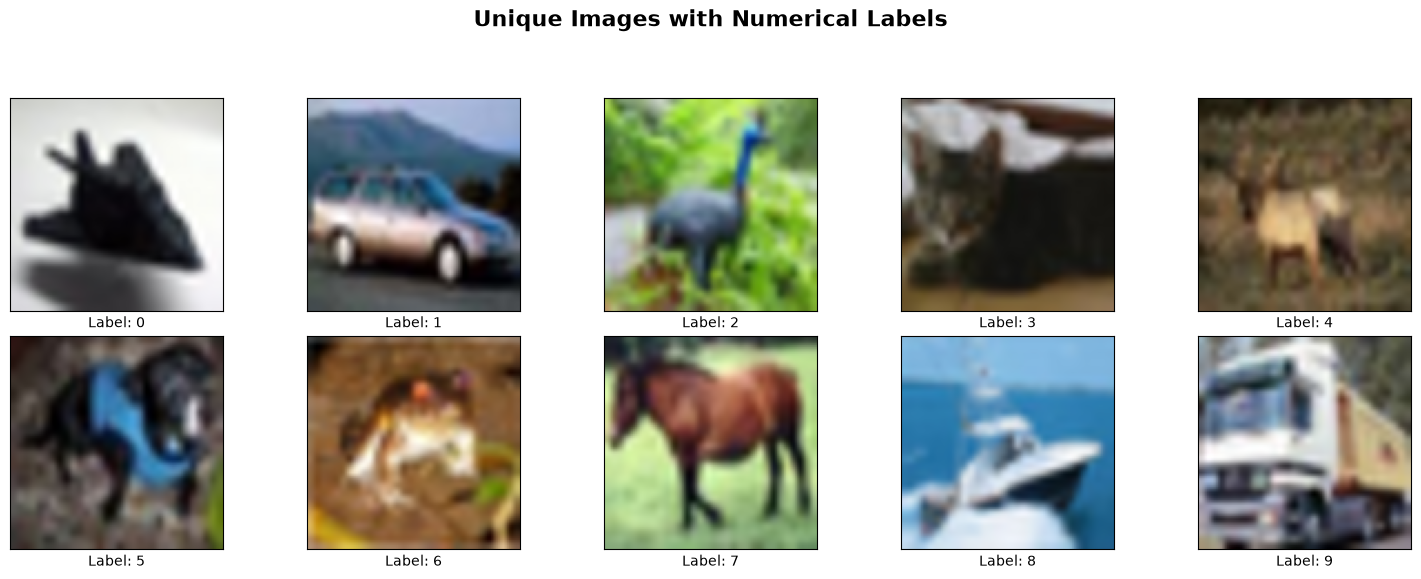

In [5]:
unique_labels, unique_indices = np.unique(
    y_train.flatten(), return_index=True
)

plt.figure(figsize=(15, 6))
plt.suptitle(
    "Unique Images with Numerical Labels",
    fontsize=16,
    fontweight="bold"
)

for i, label in enumerate(unique_labels):
    index = unique_indices[i]

    upscaled_image = tf.image.resize(
        X_train[index], (96, 96), method="bicubic"
    ).numpy()

    clipped_image = np.clip(upscaled_image, 0, 1)

    plt.subplot(2, 5, i + 1)
    plt.imshow(clipped_image)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"Label: {int(label)}")
    plt.grid(False)

plt.tight_layout(rect=[0, 0.03, 1, 0.92])
plt.show()

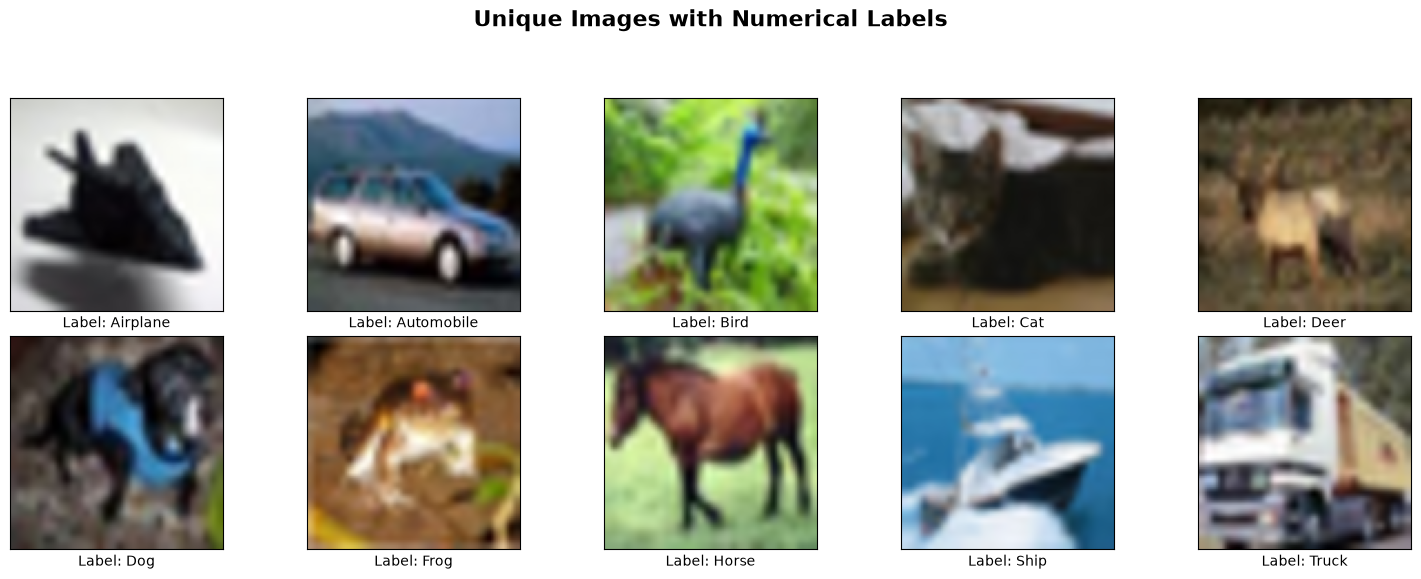

In [6]:
class_names = ["Airplane", "Automobile", "Bird", "Cat", "Deer",
               "Dog", "Frog", "Horse", "Ship", "Truck"]
unique_labels, unique_indices = np.unique(
    y_train.flatten(), return_index=True
)

plt.figure(figsize=(15, 6))
plt.suptitle(
    "Unique Images with Numerical Labels",
    fontsize=16,
    fontweight="bold"
)

for i, label in enumerate(unique_labels):
    index = unique_indices[i]

    upscaled_image = tf.image.resize(
        X_train[index], (96, 96), method="bicubic"
    ).numpy()

    clipped_image = np.clip(upscaled_image, 0, 1)

    plt.subplot(2, 5, i + 1)
    plt.imshow(clipped_image)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"Label: {class_names[int(label)]}")
    plt.grid(False)

plt.tight_layout(rect=[0, 0.03, 1, 0.92])
plt.show()

In [7]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    ),
    layers.RandomZoom(0.1)
])

In [8]:
model1 = models.Sequential(
    [
        layers.Input(shape=(32, 32, 3)),

        data_augmentation,

        layers.Resizing(64, 64, interpolation="bilinear"),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)

model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30752)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,968,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,969,738 (7.51 MB)

 Trainable params: 1,969,738 (7.51 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model2 = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    data_augmentation,

    layers.Resizing(64, 64, interpolation="bilinear"),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_1 (Resizing)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 62, 62, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 31, 31, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 29, 29, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,672,618 (6.38 MB)

 Trainable params: 1,672,618 (6.38 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model2.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stop1 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history1 = model1.fit(
    X_train, y_train,
    epochs=2,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop1]
)

In [ ]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(history1.history["loss"], color="blue", label="Loss")
axes[0].plot(history1.history["accuracy"], color="orange", label="Accuracy")
axes[0].set_title("Simple CNN")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history2.history["loss"], color="blue", label="Loss")
axes[1].plot(history2.history["accuracy"], color="orange", label="Accuracy")
axes[1].set_title("Improved CNN")
axes[1].set_xlabel("Epoch")
axes[1].legend()

fig.suptitle("Training Loss and Accuracy")
plt.tight_layout()
plt.show()

In [ ]:
test_loss1, test_acc1 = model1.evaluate(X_test, y_test, verbose=0)
test_loss2, test_acc2 = model2.evaluate(X_test, y_test, verbose=0)

print("Simple CNN")
print(f"Test Loss: {test_loss1:.4f}")
print(f"Test Accuracy: {test_acc1 * 100:.2f}%")

print("\nImproved CNN")
print(f"Test Loss: {test_loss2:.4f}")
print(f"Test Accuracy: {test_acc2 * 100:.2f}%")

In [ ]:
results = pd.DataFrame({
    "Model": ["Simple CNN", "Improved CNN"],
    "Test Loss": [test_loss1, test_loss2],
    "Test Accuracy (%)": [test_acc1 * 100, test_acc2 * 100]
})

print(results.round(2).to_string(index=False))

In [ ]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Simple CNN", "Improved CNN"],
    [test_acc1 * 100, test_acc2 * 100],
    color=["royalblue", "darkorange"],
    width=0.5
)

plt.ylabel("Test Accuracy (%)")
plt.title("CIFAR-10 Model Performance Comparison")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
if test_acc1 > test_acc2:
    print("Simple CNN performs better.")
elif test_acc2 > test_acc1:
    print("Improved CNN performs better.")
else:
    print("Both models have the same test accuracy.")

In [ ]:
index = int(input("Enter an index between 0 and 9999: "))

if 0 <= index < len(X_test):

    image = X_test[index]
    actual_label = int(y_test[index].flatten()[0])

    pred1 = model1.predict(image.reshape(1, 32, 32, 3), verbose=0)
    pred2 = model2.predict(image.reshape(1, 32, 32, 3), verbose=0)

    predicted1 = np.argmax(pred1[0])
    predicted2 = np.argmax(pred2[0])

    plt.figure(figsize=(3, 3))
    plt.imshow(image)
    plt.title(f"Actual: {class_names[actual_label]}")
    plt.axis("off")
    plt.show()

    print("Actual Class:", class_names[actual_label])
    print("\nModel 1: Simple CNN")
    print("Predicted Class:", class_names[predicted1])
    print(f"Confidence: {np.max(pred1[0]) * 100:.2f}%")
    print("Correct Prediction!" if predicted1 == actual_label
          else "Incorrect Prediction!")

    print("\nModel 2: Improved CNN")
    print("Predicted Class:", class_names[predicted2])
    print(f"Confidence: {np.max(pred2[0]) * 100:.2f}%")
    print("Correct Prediction!" if predicted2 == actual_label
          else "Incorrect Prediction!")

else:
    print("Invalid index! Enter a number from 0 to 9999.")